# **Machine Learning Modelling Workshop**

## **Learning Gate**
#### **Tecnológico de Monterrey**


**Name:**

*   René de la Calleja

**Creation Date:**

*   Aug/5/2026

In [ ]:
import os

if not os.path.exists("data"):
    print("data directory has been created.")
    os.mkdir("data")
if not os.path.exists("fig_lgt"):
    print("fig directory has been created.")
    os.mkdir("fig_lgt")
    os.mkdir("fig_lgt/profundiza")

In [ ]:
# Instalar en colab
#import sys
#
#if 'google.colab' in sys.modules:
#  !pip install -q dtreeviz

#import os
# add library module to PYTHONPATH
#sys.path.append(f"{os.getcwd()}/../")

In [ ]:
%matplotlib inline

# import standard libreries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import *

# seed to guarantee reproducibility
seed = 42

In [ ]:
# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)

# 1. Loading and Exploring the Data (EDA)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Loading the dataset in a Pandas DataFrame.
file_name = "hotels.csv"
df_hotels = pd.read_csv(file_name)

# 2. Showing dataset dimensions
print(f"dataset shape (rows, columns): {df_hotels.shape}\n")

# 3. Showing the first rows
print("First dataset rows:")
pd.set_option('display.max_columns', None) # Set option to display all columns
df_hotels.head(10)

dataset shape (rows, columns): (119390, 32)

First dataset rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,0.0,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,2015-07-03
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,2015-05-06
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,0,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,2015-04-22


In [ ]:
print("--- Variable Types in the Dataset ---")
df_hotels.info()
print("\n" + "="*50 + "\n")

#  Finding missing values per variable
print("--- Missing values per variable ---")
datos_perdidos = df_hotels.isnull().sum()
print(datos_perdidos[datos_perdidos > 0] if datos_perdidos.sum() > 0 else "No missing values in the dataset.")
print("\n" + "="*50 + "\n")

#  Spliting data in Input and Output variables, also, preventing data leakage by removing informative variables.
X = df_hotels.drop(columns=['is_canceled', 'reservation_status', 'reservation_status_date'])
y = df_hotels['is_canceled']
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print("\n" + "="*50 + "\n")

#  Getting the class distribution percentage of the dependent variable.
print("--- Class Percental Distribution in 'y' ---")
distribucion_porcentual = y.value_counts(normalize=True) * 100
print(distribucion_porcentual.map("{:.2f}%".format))

--- Variable Types in the Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 n

In [ ]:
df_hotels.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [ ]:
df_hotels.describe(include='object').T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


Finding out whether the classes are balanced.

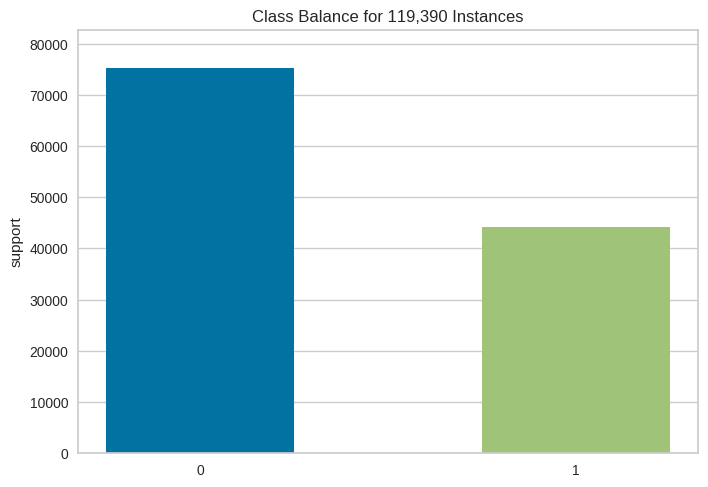

In [ ]:
from yellowbrick.target import ClassBalance
class_visualizer = ClassBalance(
	labels=[0, 1]			# Identify the classes.
									# Be careful with the label order.
)
class_visualizer.fit(df_hotels['is_canceled'])
class_visualizer.show(outpath="fig_lgt/profundiza/01_class_balance.png");

The classes are somewhat balanced.

Some Feature Engineering

In [ ]:
# Filling up Null values.
X['children'] = X['children'].fillna(0)  # Null means no kids
X['country'] = X['country'].fillna('Unknown')
X['agent'] = X['agent'].fillna(0)  # Null means there was no agent used
X['company'] = X['company'].fillna(0)  # Null means the reservation was made not by a company

In [ ]:
# Creating training, validation and test datasets
from sklearn.model_selection import train_test_split

X_train, X_rem, y_train, y_rem = train_test_split(
    X,
    y,
    train_size=0.8,   # 80% of the rows go for training.
    stratify=y,				# variable to stratify by.
    random_state=seed
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rem,
    y_rem,
    test_size=0.5,  # Split the remaining 20% into two halves.
    stratify=y_rem,
    random_state=seed
)

In [ ]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((95512, 29), (95512,), (11939, 29), (11939,), (11939, 29), (11939,))

In [ ]:
# Verifying class distributions.
distTrain = y_train.value_counts(normalize=True) * 100
distVal = y_val.value_counts(normalize=True) * 100
distTest = y_test.value_counts(normalize=True) * 100

print(distTrain.map("{:.2f}%".format))
print(distVal.map("{:.2f}%".format))
print(distTest.map("{:.2f}%".format))


is_canceled
0    62.96%
1    37.04%
Name: proportion, dtype: object
is_canceled
0    62.95%
1    37.05%
Name: proportion, dtype: object
is_canceled
0    62.96%
1    37.04%
Name: proportion, dtype: object


In [ ]:
# Encoding categorical values with Target Encoding to prevent column explosion
from sklearn.preprocessing import TargetEncoder

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

encoder = TargetEncoder(smooth="auto", random_state=seed)
X_train_encoded = X_train.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_cols] = encoder.fit_transform(X_train[categorical_cols], y_train)
X_val_encoded[categorical_cols] = encoder.transform(X_val[categorical_cols])
X_test_encoded[categorical_cols] = encoder.transform(X_test[categorical_cols])

# 2. Creating a base model to be improved.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
def compute_classification_metrics(y_true, y_pred):
    '''Compute metrics for a classification problem'''
    print(f"- Precision: {precision_score(y_true, y_pred):.2f}")
    print(f"- Recall: {recall_score(y_true, y_pred):.2f}")
    print(f"- F1: {f1_score(y_true, y_pred):.2f}")

def compute_classification_cross_validation_metrics(precision_scores, recall_scores, f1_scores):
    '''Compute metrics for cross-validation '''
    print(f"- Precision: {np.mean(precision_scores):.2f}")
    print(f"- Recall: {np.mean(recall_scores):.2f}")
    print(f"- F1: {np.mean(f1_scores):.2f}")

In [ ]:
# This is the Base Model

from sklearn.tree import DecisionTreeClassifier
# Using a basic Decision Tree classifier
clf_dt = DecisionTreeClassifier(
    max_depth = 5,
    #class_weight = 'balanced', 	# Not balanced at first.
    random_state=seed
)
# Fitting the model and predicting.
clf_dt.fit(X_train_encoded, y_train)
y_pred_train = clf_dt.predict(X_train_encoded)
y_pred_val = clf_dt.predict(X_val_encoded)

In [ ]:
from sklearn.model_selection import cross_val_score
# Computing cross-validation error
precision_scores = cross_val_score(
    clf_dt,
    X_train_encoded,
    y_train,
    cv=5,
    scoring='precision'
)

recall_scores = cross_val_score(
    clf_dt,
    X_train_encoded,
    y_train,
    cv=5,
    scoring='recall'
)

f1_scores = cross_val_score(
    clf_dt,
    X_train_encoded,
    y_train,
    cv=5,
    scoring='f1'
)

In [ ]:
print("Evaluation on training from cross-validation:")
compute_classification_cross_validation_metrics(precision_scores, recall_scores, f1_scores)
print()
print("Evaluation on training:")
compute_classification_metrics(y_train, y_pred_train)
print()
print("Evaluation on validation:")
compute_classification_metrics(y_val, y_pred_val)

Evaluation on training from cross-validation:
- Precision: 0.89
- Recall: 0.50
- F1: 0.61

Evaluation on training:
- Precision: 0.99
- Recall: 0.38
- F1: 0.54

Evaluation on validation:
- Precision: 0.99
- Recall: 0.37
- F1: 0.54


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


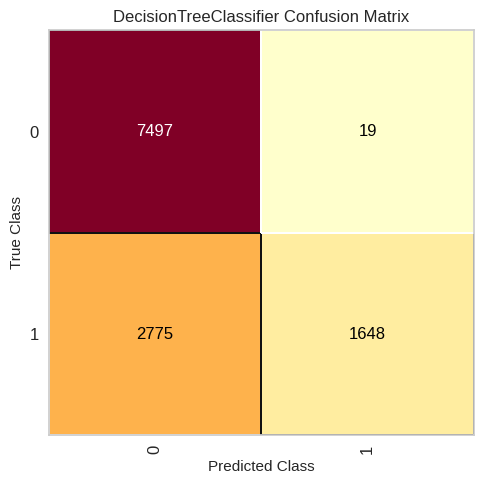

In [ ]:
from yellowbrick.classifier import ConfusionMatrix
fig, ax = plt.subplots(figsize = (5,5))
# Let's build the confusion matrix
cm = ConfusionMatrix(
    clf_dt,
    classes=[0, 1]		# Identify the classes.
    							# Be careful with the label order
)

cm.fit(X_train_encoded, y_train)
cm.score(X_val_encoded, y_val)
cm.show(outpath="fig_lgt/profundiza/08_matriz_confusion.png");

As we can see from the confusion matrix this base model is good at predicting those clients that don't cancel a reservation, but it's very poor when it comes to those that cancel reservations and that's our main goal.

This is also reflected in the scores of the metrics shown above, where Recall is just 0.37 and F1 = 0.54

So we have a lot of false negatives that we need to fix.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
def f_print_evaluation_metrics(y_true, y_pred):
    '''Print precision, recall and f1 score results.

    Parameters
    ----------
    y_true (ndarray): Array with the true classes
    y_pred (ndarray): Array with predicted classes
    '''
    print("precision_score: {}".format(np.round(precision_score(y_true, y_pred), 3)))
    print("recall_score: {}".format(np.round(recall_score(y_true, y_pred), 3)))
    print("f1_score: {}".format(np.round(f1_score(y_true, y_pred), 3)))

In [ ]:
f_print_evaluation_metrics(y_val, y_pred_val)

precision_score: 0.989
recall_score: 0.373
f1_score: 0.541


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


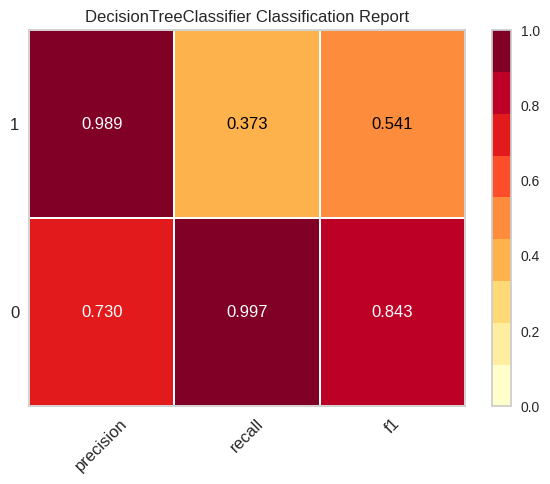

In [ ]:
from yellowbrick.classifier import ClassificationReport
fig, ax = plt.subplots(figsize = (6,5))
visualizer = ClassificationReport(
    clf_dt,				# The model
    classes=[0, 1]		# Identify the classes.
    							# Be careful with the label order.
)

visualizer.fit(X_train_encoded, y_train)
visualizer.score(X_val_encoded, y_val)
visualizer.show("fig_lgt/profundiza/08_reporte_clasificacion_desicion_tree.png");

Precision and recall curves for base model

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


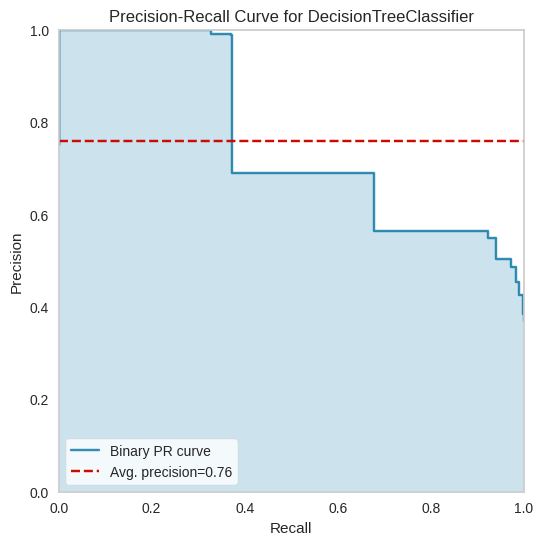

In [ ]:
from yellowbrick.classifier import PrecisionRecallCurve
# Let's specify the precision and recall curves
fig, ax = plt.subplots(figsize = (6,6))
viz = PrecisionRecallCurve(clf_dt)

viz.fit(X_train_encoded, y_train)
# Let's evaluate with validation data.
viz.score(X_val_encoded, y_val)
viz.show("fig_lgt/profundiza/08_precision_recall.png");

The curve reflects that at a good precision we have a quite low recall and vice versa.

ROC & AUC curves for base model

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names


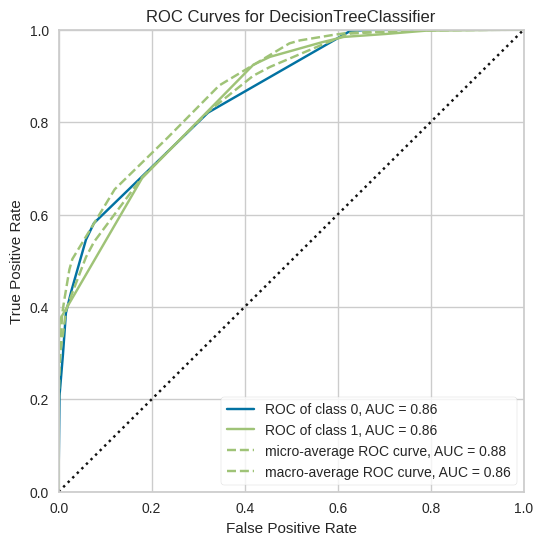

In [ ]:
from yellowbrick.classifier import ROCAUC
# Let's specify ROC AUC curve
fig, ax = plt.subplots(figsize = (6,6))
roc_curves_visualizer = ROCAUC(
    clf_dt,					# The model
    classes=[0, 1]
)

roc_curves_visualizer.fit(X_train_encoded, y_train)
roc_curves_visualizer.score(X_val_encoded, y_val)
roc_curves_visualizer.show("fig_lgt/profundiza/08_precision_recall.png");

This graph also reflects a poor performance of our model.

# 3. Implementation of a Complex Model (Random Forest)

Domain-Specific Feature Engineering (Creating New Variables)

In [ ]:
# Total staying nights
X['total_nights'] = X['stays_in_weekend_nights'] + X['stays_in_week_nights']

# Total group size
X['total_people'] = X['adults'] + X['children'] + X['babies']

In [ ]:
# Split again in Train, Validation and Test
X_train, X_rem, y_train, y_rem = train_test_split(
    X, y,
    train_size=0.8,   # 80% of the rows go to training.
    stratify=y,				# variable to stratify by.
    random_state=seed
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rem, y_rem,
    test_size=0.5,  # Split the remaining 20% into two halves.
    stratify=y_rem,
    random_state=seed
)

In [ ]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((95512, 31), (95512,), (11939, 31), (11939,), (11939, 31), (11939,))

In [ ]:
# Verifying distributions.
distTrain = y_train.value_counts(normalize=True) * 100
distVal = y_val.value_counts(normalize=True) * 100
distTest = y_test.value_counts(normalize=True) * 100

print(distTrain.map("{:.2f}%".format))
print(distVal.map("{:.2f}%".format))
print(distTest.map("{:.2f}%".format))

is_canceled
0    62.96%
1    37.04%
Name: proportion, dtype: object
is_canceled
0    62.95%
1    37.05%
Name: proportion, dtype: object
is_canceled
0    62.96%
1    37.04%
Name: proportion, dtype: object


In [ ]:
# Split features into categorical vs numerical arrays for targeted selection
from sklearn.preprocessing import OrdinalEncoder

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

# Ordinal Encoding for Categorical variables (Keeps them separated from numerical flow)
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_encoded = X_train.copy()
X_val_encoded = X_val.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_cols] = encoder.fit_transform(X_train[categorical_cols])
X_val_encoded[categorical_cols] = encoder.transform(X_val[categorical_cols])
X_test_encoded[categorical_cols] = encoder.transform(X_test[categorical_cols])

Now let's do variable selection:

Selected Categorical Features: ['deposit_type', 'country', 'market_segment', 'assigned_room_type', 'distribution_channel', 'customer_type', 'hotel']


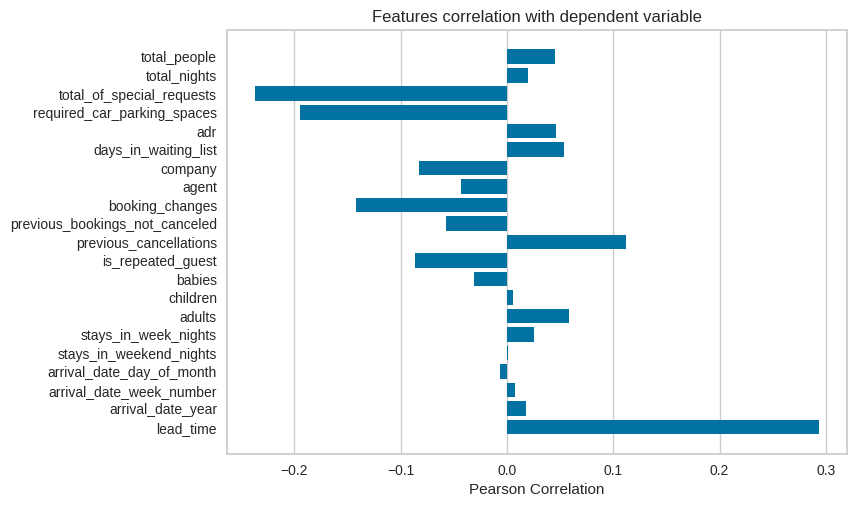

Optimal number of numerical features identified: 19
Selected Numerical Features via RFECV: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_people']


In [ ]:
from sklearn.feature_selection import mutual_info_classif, RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from yellowbrick.target import FeatureCorrelation

# --- A. CATEGORICAL SELECTION: Mutual Information ---
# Measures non-linear dependency between categorical features and the target
mi_scores = mutual_info_classif(X_train_encoded[categorical_cols], y_train, random_state=seed)
mi_series = pd.Series(mi_scores, index=categorical_cols).sort_values(ascending=False)

# Keep categorical variables with a score > 0.01 (drops weak predictors)
selected_categorical = mi_series[mi_series > 0.01].index.tolist()
print("Selected Categorical Features:", selected_categorical)

# --- B. NUMERICAL SELECTION: Yellowbrick Feature Correlation ---
# Visualizes and evaluates linear relationships
visualizer = FeatureCorrelation(labels=numeric_cols, col_clear=True)
visualizer.fit(X_train_encoded[numeric_cols], y_train)
visualizer.show() # Renders the correlation plot

# --- C. NUMERICAL SELECTION: Recursive Feature Elimination with Cross-Validation (RFECV) ---
# RFE uses a preliminary estimator to prune uninformative numeric variables
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
rfecv_selector = RFECV(
    estimator=RandomForestClassifier(n_estimators=50, max_depth=8, random_state=seed, n_jobs=-1),
    step=2,
    cv=cv_strategy,
    scoring='roc_auc', # Optimizes for the area under the ROC curve
    n_jobs=-1
)

rfecv_selector.fit(X_train_encoded[numeric_cols], y_train)

# Identify the automatically selected optimal numerical features
selected_numeric = np.array(numeric_cols)[rfecv_selector.support_].tolist()
print(f"Optimal number of numerical features identified: {rfecv_selector.n_features_}")
print("Selected Numerical Features via RFECV:", selected_numeric)

# --- D. CONSOLIDATE FINAL DATASETS ---
final_features = selected_categorical + selected_numeric

X_train_final = X_train_encoded[final_features]
X_val_final = X_val_encoded[final_features]
X_test_final = X_test_encoded[final_features]


Let's try with a RandomForestClassifier with hard coded parameters first:


=== Random Forest Performance (Validation Set) ===
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      7516
           1       0.82      0.85      0.83      4423

    accuracy                           0.87     11939
   macro avg       0.86      0.87      0.87     11939
weighted avg       0.87      0.87      0.87     11939

ROC-AUC Score: 0.9484


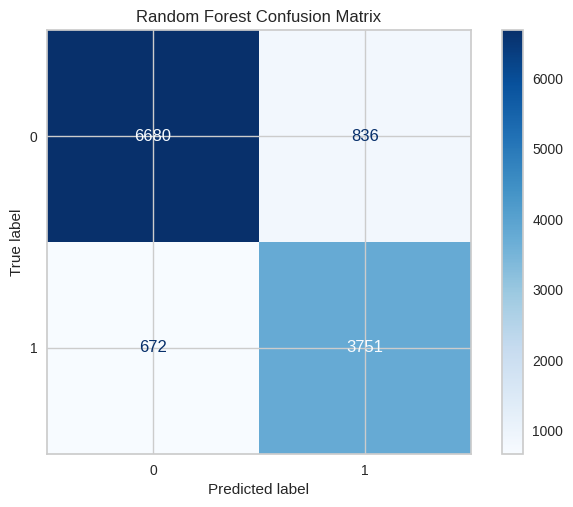

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Initialize Complex Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    random_state=seed,
    n_jobs=-1,
    class_weight="balanced" # Addresses class imbalance directly inside the forest nodes
)

# Train the model
rf_model.fit(X_train_final, y_train)

# Evaluate on the validation set
y_val_pred = rf_model.predict(X_val_final)
y_val_proba = rf_model.predict_proba(X_val_final)[:, 1]

print("\n=== Random Forest Performance (Validation Set) ===")
print(classification_report(y_val, y_val_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")

# Plot Confusion Matrix
ConfusionMatrixDisplay.from_estimator(rf_model, X_val_final, y_val, cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.show()


Compared to the base model's results we have much better values now for recall an F1-score, these being:


In [ ]:
f_print_evaluation_metrics(y_val, y_val_pred)

precision_score: 0.818
recall_score: 0.848
f1_score: 0.833


Now let's implement Hyperparameter Tuning via RandomizedSearchCV

=== Starting Hyperparameter Tuning ===
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Hyperparameters Found:
{'n_estimators': 250, 'min_samples_split': 15, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}
Best Training Cross-Validation ROC-AUC: 0.9472

=== Optimized Random Forest Performance (Validation Set) ===
              precision    recall  f1-score   support

           0       0.91      0.89      0.90      7516
           1       0.83      0.85      0.84      4423

    accuracy                           0.88     11939
   macro avg       0.87      0.87      0.87     11939
weighted avg       0.88      0.88      0.88     11939

Validation ROC-AUC Score: 0.9510


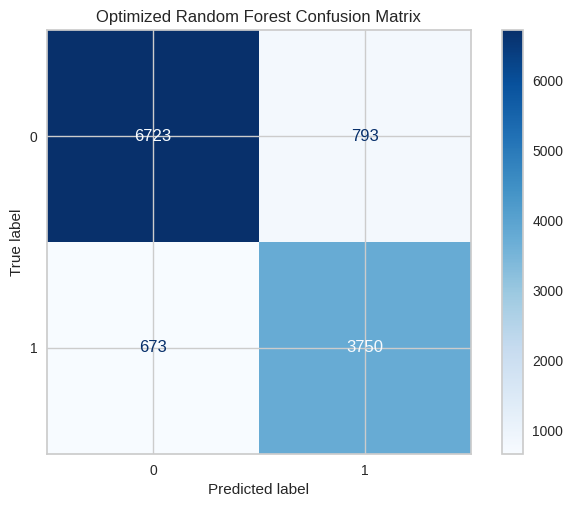

In [ ]:
import numpy as np
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Define the Hyperparameter Search Space
# We focus on parameters that control model capacity and prevent overfitting
param_dist = {
    'n_estimators':[50, 100, 200, 250],                  # Number of trees in the forest
    'max_depth': [5, 10, 15, 20],                     # Maximum depth of the tree
    'min_samples_split': [2, 5, 10, 15],                     # Minimum samples required to split a node
    'min_samples_leaf':[1, 3, 5, 10],                       # Minimum samples required at a leaf node
    'max_features': ['sqrt', 'log2'],              # Number of features to consider at each split
    'class_weight': ['balanced', 'balanced_subsample']   # Weights associated with classes
}

# 2. Initialize the Base Random Forest Estimator
rf_base = RandomForestClassifier(random_state=seed, n_jobs=-1)

# 3. Setup Cross-Validation and the Randomized Search
# StratifiedKFold maintains the binary class balance across all folds
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=15,               # Number of random combinations to try (adjust based on computing power)
    cv=cv_strategy,
    scoring='roc_auc',       # Optimize for ROC-AUC to balance True Positives and False Positives
    random_state=seed,
    n_jobs=-1,
    verbose=2                # Shows training progress logs
)

# 4. Run the Search on the Selected Features
print("=== Starting Hyperparameter Tuning ===")
random_search.fit(X_train_final, y_train)

# 5. Extract and Review the Best Configuration
best_rf_model = random_search.best_estimator_
print("\nBest Hyperparameters Found:")
print(random_search.best_params_)
print(f"Best Training Cross-Validation ROC-AUC: {random_search.best_score_:.4f}")

# 6. Evaluate the Optimized Model on the Validation Set
y_val_pred = best_rf_model.predict(X_val_final)
y_val_proba = best_rf_model.predict_proba(X_val_final)[:, 1]

print("\n=== Optimized Random Forest Performance (Validation Set) ===")
print(classification_report(y_val, y_val_pred))
print(f"Validation ROC-AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")

# 7. Plot the Final Confusion Matrix
ConfusionMatrixDisplay.from_estimator(best_rf_model, X_val_final, y_val, cmap='Blues')
plt.title("Optimized Random Forest Confusion Matrix")
plt.show()


In [ ]:
f_print_evaluation_metrics(y_val, y_val_pred)

precision_score: 0.825
recall_score: 0.848
f1_score: 0.836


ROC & AUC curves for the best Random Forest Classifier

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names


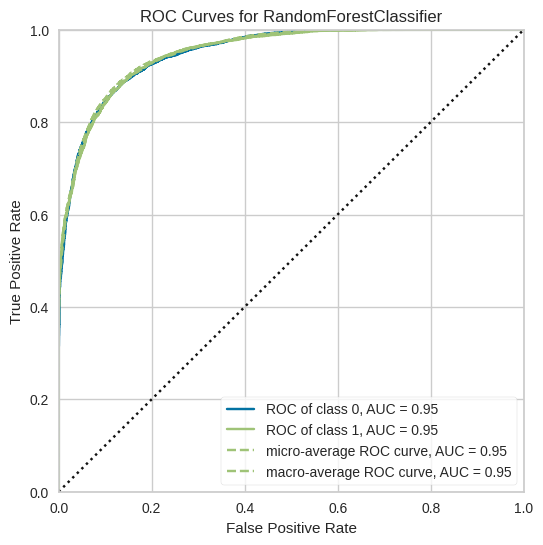

In [ ]:
# Let's specify ROC AUC curve
fig, ax = plt.subplots(figsize = (6,6))
roc_curves_visualizer = ROCAUC(
    best_rf_model,					# The model
    classes=[0, 1]
)

roc_curves_visualizer.fit(X_train_final, y_train)
roc_curves_visualizer.score(X_val_final, y_val)
roc_curves_visualizer.show("fig_lgt/profundiza/ROC_AUC_final.png");

We obtained now a much better curve with high true positive rates implying low false positive rates.

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names


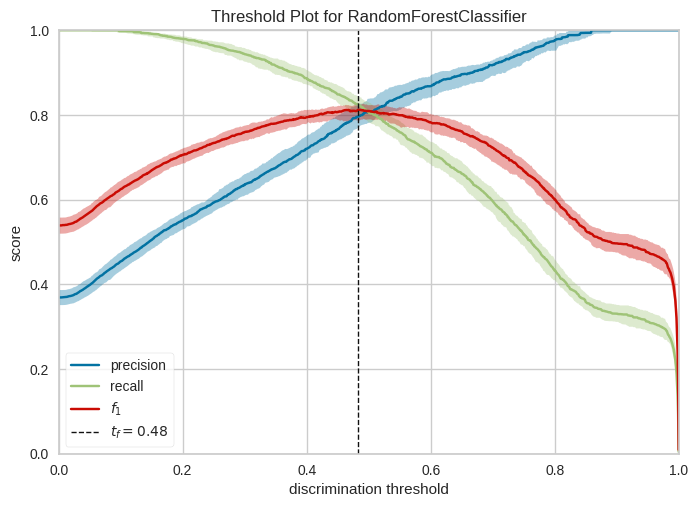

In [ ]:
from yellowbrick.classifier.threshold import DiscriminationThreshold

visualizer = DiscriminationThreshold(
 best_rf_model, # The model
 exclude = ["queue_rate"]
)
# We adjust the visualizer to the validation data
visualizer.fit(X_val_final, y_val)
visualizer.show();

# 4. Probabilities Calibration

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import log_loss, brier_score_loss
import xgboost as xgb
from matplotlib.gridspec import GridSpec

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.calibration import CalibrationDisplay


def plot_calibration_curves(list_fitted_models, X_test, y_test, fig_name = "calibration_curves_1.png"):
    """
    Plot calibration curves for multiple fitted models.

    Parameters:
    -----------
    list_fitted_models : list of tuples (fitted_model, model_name)
    X_test : array-like
        Test features
    y_test : array-like
        Test labels

    Returns:
    --------
    calibration_displays : dict
        Models to objects of CalibrationDisplay mapping dictionary.
    """
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = plt.get_cmap("Dark2")

    calibration_displays = {}
    markers = ["^", "v", "s", "o"]

    for i, (clf, name) in enumerate(list_fitted_models):
        display = CalibrationDisplay.from_estimator(
            clf,
            X_test,
            y_test,
            n_bins=10,
            name=name,
            ax=ax,
            color=colors(i),
            marker=markers[i],
        )
        calibration_displays[name] = display

    ax.grid()
    ax.set_title("Calibration Curves")
    plt.savefig(f"fig_lgt/{fig_name}")
    plt.show()

    return calibration_displays

In [ ]:
prob_true, prob_pred = calibration_curve(y_val, best_rf_model.predict_proba(X_val_final)[:,1], n_bins=10)

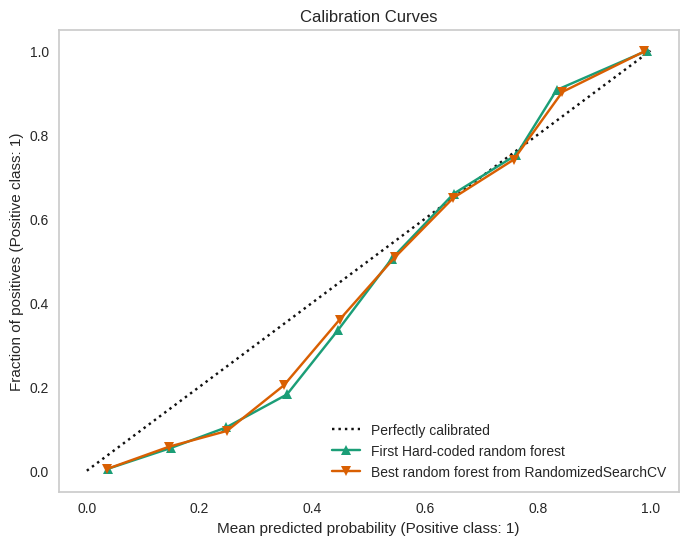

In [ ]:
# The trained models
clf_list = [
    (rf_model, "First Hard-coded random forest"),
    (best_rf_model, "Best random forest from RandomizedSearchCV")
]

calibration_curves_dict = plot_calibration_curves(clf_list, X_val_final, y_val, fig_name = "profundiza/calibration_curves_1.png")

Looking at the calibration curves we can see the predicted probability in the range from 0.0 to 0.6 is lower than the real frequency for positive observations. And in the range from 0.9 to 1.0 it's a little higher than the true frequency. This happens for both of the models so we can work on improving these probabilities.

Let's try with the Sigmoid and Isotonic methods:

In [ ]:
from sklearn.frozen import FrozenEstimator
from sklearn.calibration import CalibratedClassifierCV
# Calibration with Platt method (Sigmoid)

rf_clf_sigmoid = CalibratedClassifierCV(estimator=FrozenEstimator(best_rf_model), cv="prefit", method="sigmoid")
rf_clf_sigmoid.fit(X_val_final, y_val)
rf_prob_pos_sigmoid = rf_clf_sigmoid.predict_proba(X_val_final)[:, 1]

/usr/local/lib/python3.12/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.


In [ ]:
rf_prob_pos_sigmoid

array([0.97399557, 0.01523561, 0.03418874, ..., 0.15498833, 0.96753945,
       0.47294387])

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# Non parametric calibration with Isotonic method.
rf_clf_isotonic = CalibratedClassifierCV(estimator=FrozenEstimator(best_rf_model), cv="prefit", method="isotonic")
rf_clf_isotonic.fit(X_val_final, y_val)
rf_prob_pos_isotonic = rf_clf_isotonic.predict_proba(X_val_final)[:, 1]

/usr/local/lib/python3.12/dist-packages/sklearn/calibration.py:333: UserWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.


In [ ]:
rf_prob_pos_isotonic

array([1.        , 0.        , 0.05251641, ..., 0.18009479, 1.        ,
       0.47154472])

In [ ]:
from sklearn.metrics import brier_score_loss

# Non calibrated probabilities.
rf_y_val_pred = best_rf_model.predict_proba(X_val_final)[:, 1]
print("Brier score losses: (the smaller the better)")

# Computing brier score on non calibrated model.
rf_clf_score = brier_score_loss(y_val, rf_y_val_pred)
print("Model non calibrated: %1.3f" % rf_clf_score)

# Computing brier score on calibrated model.
rf_clf_sigmoid_score = brier_score_loss(y_val, rf_prob_pos_sigmoid)
print("Model calibrated with sigmoide method: %1.3f" % rf_clf_sigmoid_score)

Brier score losses: (the smaller the better)
Model non calibrated: 0.091
Model calibrated with sigmoide method: 0.086


In [ ]:
from sklearn.metrics import brier_score_loss

# Non calibrated probabilities.
rf_y_val_pred = best_rf_model.predict_proba(X_val_final)[:, 1]
print("Brier score losses: (the smaller the better)")

# Computing brier score on non calibrated model.
rf_clf_score = brier_score_loss(y_val, rf_y_val_pred)
print("Model non calibrated: %1.3f" % rf_clf_score)

# Computing brier score on calibrated model.
rf_clf_isotonic_score = brier_score_loss(y_val, rf_prob_pos_isotonic)
print("Model calibrated with isotonic method: %1.3f" % rf_clf_isotonic_score)

Brier score losses: (the smaller the better)
Model non calibrated: 0.091
Model calibrated with isotonic method: 0.084


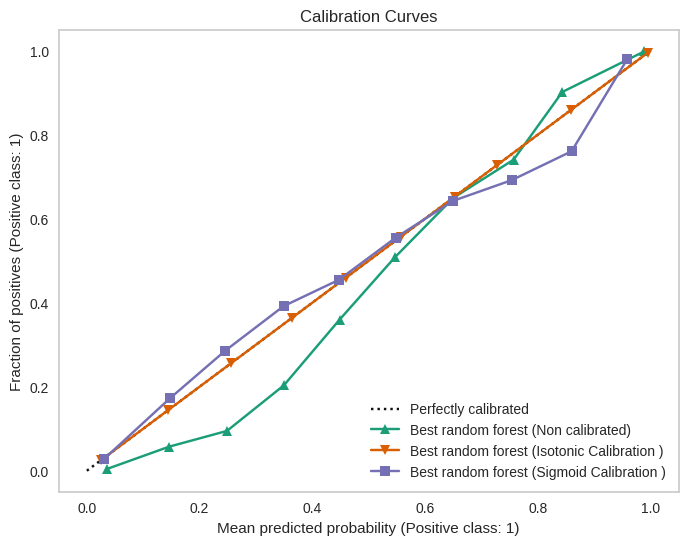

In [ ]:
# The models to plot.
calibrated_clf_list = [
    (best_rf_model, "Best random forest (Non calibrated)"),
    (rf_clf_isotonic, "Best random forest (Isotonic Calibration )"),
    (rf_clf_sigmoid, "Best random forest (Sigmoid Calibration )")
]
# Plotting calibration curves.
corrected_calibration_curves_dict = plot_calibration_curves(calibrated_clf_list, X_val_final, y_val, fig_name = "profundiza/calibration_curves_2.png")

We can see now that the calibrated probabilities adjust much better to the real observed frequency of positives, especially the Isotonic one.

# 5. Evaluating the calibrated classification model on the Test dataset.

In [ ]:
rf_clf_isotonic.predict(X_test_final)

array([1, 0, 0, ..., 0, 1, 0])

In [ ]:
rf_clf_isotonic.predict_proba(X_test_final)[:, 1]

array([0.72350993, 0.28806584, 0.00946746, ..., 0.00946746, 1.        ,
       0.08383234])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names


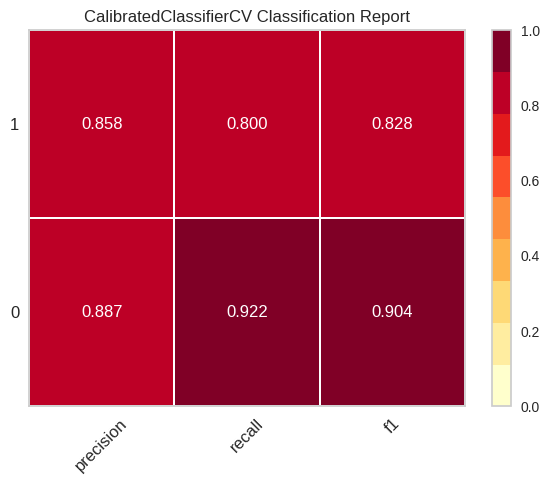

In [ ]:
fig, ax = plt.subplots(figsize = (6,5))
visualizer = ClassificationReport(
    rf_clf_isotonic,				# The model
    classes=[0, 1]
)

visualizer.fit(X_train_final, y_train)
visualizer.score(X_test_final, y_test)

visualizer.show("fig_lgt/profundiza/reporte_calisficacion_calibrado.png");

In [ ]:
rf_clf_isotonic

CalibratedClassifierCV(cv='prefit',
                       estimator=FrozenEstimator(estimator=RandomForestClassifier(class_weight='balanced',
                                                                                  max_depth=20,
                                                                                  min_samples_leaf=10,
                                                                                  min_samples_split=15,
                                                                                  n_estimators=250,
                                                                                  n_jobs=-1,
                                                                                  random_state=42)),
                       method='isotonic')


=== Classification Report on Test set ===
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      7517
           1       0.86      0.80      0.83      4422

    accuracy                           0.88     11939
   macro avg       0.87      0.86      0.87     11939
weighted avg       0.88      0.88      0.88     11939

ROC-AUC Score on Test: 0.9493


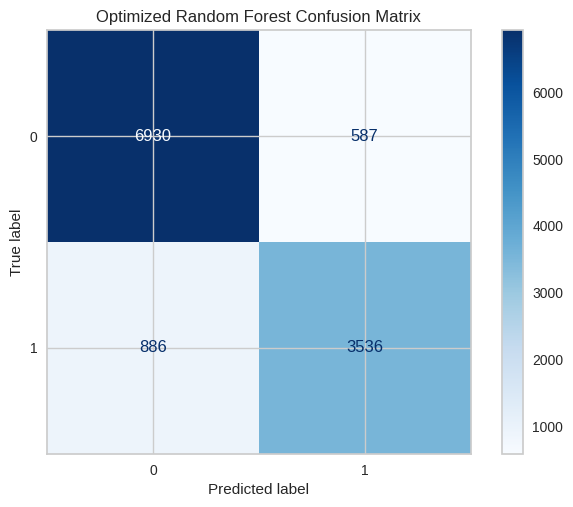

In [ ]:
# Evaluate the Calibrated Isotonic Model on the Test Set
y_test_pred = rf_clf_isotonic.predict(X_test_final)
y_test_proba = rf_clf_isotonic.predict_proba(X_test_final)[:, 1]

print("\n=== Classification Report on Test set ===")
print(classification_report(y_test, y_test_pred))
print(f"ROC-AUC Score on Test: {roc_auc_score(y_test, y_test_proba):.4f}")

# Plot the Final Confusion Matrix
ConfusionMatrixDisplay.from_estimator(rf_clf_isotonic, X_test_final, y_test, cmap='Blues')
plt.title("Optimized Random Forest Confusion Matrix")
plt.show()

Looking at the results in the Classification Report and the confusion matrix we can conclude that:

1. We have a good recall for the positive class (recall = 0.8), this is maybe the data in which we have more interest, to find the customers that will cancel a reservation.

2. Regarding the precision, it is better (precision = 0.85), and the numbers are even better for the negative class, it is also helpful to know what customers will NOT cancel the reservation.

3. F1-score is quite good compared to that from the Best Random Forest found, so considering we are evaluating the model on a dataset that it has never seen and that now the probabilities are well calibrated we can say that we have a quite good model to deploy on a production application.

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names


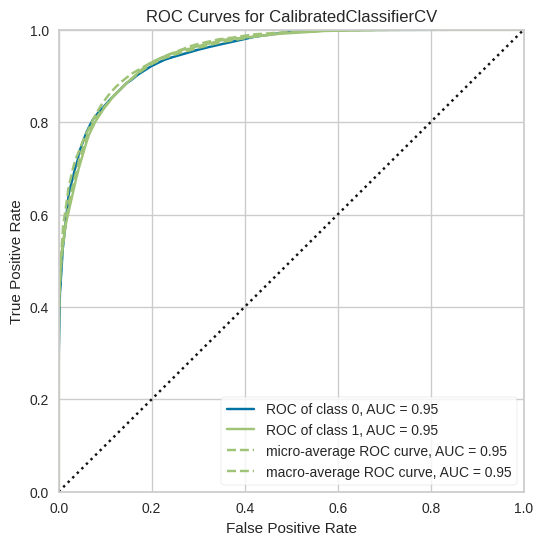

In [ ]:
# Plotting ROC AUC curves
fig, ax = plt.subplots(figsize = (6,6))
roc_curves_visualizer = ROCAUC(
    rf_clf_isotonic,					# The model
    classes=[0, 1]
)

roc_curves_visualizer.fit(X_train_final, y_train)
roc_curves_visualizer.score(X_test_final, y_test)
roc_curves_visualizer.show("fig_lgt/profundiza/ROC_AUC_final_on_test.png");

# 6. Generating a .csv file with the final results from the calibrated model run on test dataset.

In [ ]:
# 1. Extract the original reservation identifier
# Since the index of X_test tracks the unique row positions of the original dataset,
# we can safely pull it to serve as the unique reservation identifier.
reservation_ids = X_test.index

# 2. Construct the output DataFrame
results_df = pd.DataFrame({
    'reservation_id': reservation_ids,
    'calibrated_probability_of_cancellation': y_test_proba,
    'predicted_class': y_test_pred
})

# 3. Export to a CSV file
output_filename = 'hotel_test_predictions_calibrated.csv'
results_df.to_csv(output_filename, index=False)

print(f"=== Export Complete ===")
print(f"Successfully generated '{output_filename}' with {len(results_df)} rows.")
print("\nPreview of the final predictions:")
print(results_df.head())


=== Export Complete ===
Successfully generated 'hotel_test_predictions_calibrated.csv' with 11939 rows.

Preview of the final predictions:
   reservation_id  calibrated_probability_of_cancellation  predicted_class
0           69797                                0.723510                1
1           27558                                0.288066                0
2           88802                                0.009467                0
3           52171                                0.777778                1
4           45033                                0.000000                0


# 7. Saving the model in a .joblib file

1. Define Custom Transformers for Preprocessing & Selection

In [ ]:
import pandas as pd
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import mutual_info_classif, RFECV

class HotelFeatureEngineer(BaseEstimator, TransformerMixin):
    """Fills null values and creates the custom engineered features."""
    def __init__(self):
        self.categorical_cols = ['hotel', 'arrival_date_month', 'meal', 'country',
                                 'market_segment', 'distribution_channel',
                                 'reserved_room_type', 'assigned_room_type', 'customer_type']

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        # Drop leakage variables if present
        X_out.drop(columns=['reservation_status', 'reservation_status_date'], inplace=True, errors='ignore')

        # Null Imputation
        X_out['children'] = X_out['children'].fillna(0)
        X_out['country'] = X_out['country'].fillna('Unknown')
        X_out['agent'] = X_out['agent'].fillna(0)
        X_out['company'] = X_out['company'].fillna(0)

        # Feature Engineering
        X_out['total_nights'] = X_out['stays_in_weekend_nights'] + X_out['stays_in_week_nights']
        X_out['total_people'] = X_out['adults'] + X_out['children'] + X_out['babies']

        # Ensure categorical columns remain objects for downstream OrdinalEncoder
        for col in self.categorical_cols:
            if col in X_out.columns:
                X_out[col] = X_out[col].astype(str)

        return X_out

class HybridFeatureSelector(BaseEstimator, TransformerMixin):
    """Executes Mutual Info on Categorical features and RFECV on Numeric features."""
    def __init__(self, categorical_cols, numeric_cols, rfecv_estimator, cv_strategy):
        self.categorical_cols = categorical_cols
        self.numeric_cols = numeric_cols
        self.rfecv_estimator = rfecv_estimator
        self.cv_strategy = cv_strategy
        self.selected_features_ = None

    def fit(self, X, y):
        # 1. Categorical Selection using Mutual Information
        mi_scores = mutual_info_classif(X[self.categorical_cols], y, random_state=seed)
        mi_series = pd.Series(mi_scores, index=self.categorical_cols)
        selected_cat = mi_series[mi_series > 0.01].index.tolist()

        # 2. Numerical Selection using RFECV
        rfecv = RFECV(
            estimator=self.rfecv_estimator,
            step=2,
            cv=self.cv_strategy,
            scoring='roc_auc',
            n_jobs=-1
        )
        rfecv.fit(X[self.numeric_cols], y)
        selected_num = np.array(self.numeric_cols)[rfecv.support_].tolist()

        # Combine lists to define final feature space
        self.selected_features_ = selected_cat + selected_num
        return self

    def transform(self, X):
        # Slice columns dynamically based on what was selected during fit()
        return X[self.selected_features_]


2: Set Up Data Split & Target Encoders

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn import set_config

# Set scikit-learn to output pandas DataFrames for transformers
set_config(transform_output="pandas")

# Raw Stratified 80/10/10 Split
X = df_hotels.drop(columns=['is_canceled'])
y = df_hotels['is_canceled']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, train_size=0.80, random_state=seed, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=seed, stratify=y_temp)

# Identify feature categories (incorporating columns that will be engineered)
categorical_features = ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
                        'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'customer_type']

numeric_features = ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month',
                    'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
                    'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled',
                    'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr',
                    'required_car_parking_spaces', 'total_of_special_requests',
                    'total_nights', 'total_people']

# Build ColumnTransformer to process categorical streams cleanly
encoder_transformer = ColumnTransformer(
    transformers=[
        ('cat_encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features)
    ],
    remainder='passthrough', # Numeric columns pass through unchanged
    verbose_feature_names_out=False
)

3 Assembly of the Processing & Tuning Pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Auxiliary cross-validation strategy
cv_strat = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
rf_selector_engine = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=seed, n_jobs=-1)

# Build the foundational Pipeline
tuning_pipeline = Pipeline(steps=[
    ('engineer', HotelFeatureEngineer()),
    ('encoder', encoder_transformer),
    ('selector', HybridFeatureSelector(categorical_features, numeric_features, rf_selector_engine, cv_strat)),
    ('classifier', RandomForestClassifier(random_state=seed, n_jobs=-1))
])

# Define the RandomizedSearchCV distribution grid
# Notice the prefix 'classifier__' matching the pipeline step name
param_dist = {
    'classifier__n_estimators': [50, 100, 200, 250],
    'classifier__max_depth': [5, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10, 15],
    'classifier__min_samples_leaf': [1, 3, 5, 10],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

# Run optimization across the whole processing graph
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_dist,
    n_iter=15,
    cv=cv_strat,
    scoring='roc_auc',
    random_state=seed,
    n_jobs=-1,
    verbose=1
)

print("=== Tuning Entire Pipeline Structure ===")
random_search.fit(X_train, y_train)

# Extract optimized base pipeline
best_processing_pipeline = random_search.best_estimator_
print("Optimization finished successfully.")


=== Tuning Entire Pipeline Structure ===
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Optimization finished successfully.


4 Isotonic Calibration & Serialization

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, roc_auc_score
import joblib
from sklearn.frozen import FrozenEstimator

# Calibrate the finalized scikit-learn workflow
production_pipeline = CalibratedClassifierCV(
    estimator=FrozenEstimator(best_processing_pipeline), # Wrap the pre-fitted estimator
    cv=None,
    method="isotonic"
)
# Calibrate weights using validation data
production_pipeline.fit(X_val, y_val)

# Verify performance on completely untouched Test data
y_test_pred = production_pipeline.predict(X_test)
y_test_proba = production_pipeline.predict_proba(X_test)[:, 1]

print("\n=== FINAL TEST RESULTS FROM INTEGRATED SKLEARN PIPELINE ===")
print(classification_report(y_test, y_test_pred))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_test_proba):.4f}")

# Save the unified pipeline asset to disk
joblib.dump(production_pipeline, 'hotel_calibrated_pipeline.pkl', compress=3)
print("\n[SUCCESS] Unified scikit-learn artifact saved as 'hotel_calibrated_pipeline.pkl'")


=== FINAL TEST RESULTS FROM INTEGRATED SKLEARN PIPELINE ===
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      7517
           1       0.85      0.81      0.83      4422

    accuracy                           0.88     11939
   macro avg       0.87      0.86      0.87     11939
weighted avg       0.88      0.88      0.88     11939

Test ROC-AUC Score: 0.9492

[SUCCESS] Unified scikit-learn artifact saved as 'hotel_calibrated_pipeline.pkl'


### Production Usage Example

In [ ]:
raw_api_dataframe = pd.DataFrame([{
    'lead_time': 45,
    'hotel': 'City Hotel',
    'country': 'PRT',
    # ... all other required columns
}])

loaded_model = joblib.load('hotel_calibrated_pipeline.pkl')
probabilities = loaded_model.predict_proba(raw_api_dataframe)[:, 1]